In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("ec2_cpu_utilization_5f5533.csv", parse_dates=["timestamp"])

In [3]:
df = df.sort_values("timestamp").reset_index(drop=True)

In [4]:
df.head()

,timestamp,value
0,2014-02-14 14:27:00,51.846
1,2014-02-14 14:32:00,44.508
2,2014-02-14 14:37:00,41.244
3,2014-02-14 14:42:00,48.568
4,2014-02-14 14:47:00,46.714


In [5]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

In [6]:
df["year"] = df["timestamp"].dt.year
df["month"] = df["timestamp"].dt.month
df["day"] = df["timestamp"].dt.day
df["hour"] = df["timestamp"].dt.hour
df["minute"] = df["timestamp"].dt.minute

In [7]:
df["rolling_mean"] = df["value"].rolling(36).mean()
df["rolling_std"] = df["value"].rolling(36).std()

df["previous_value"] = df["value"].shift(1)
df["change"] = df["value"].diff()

In [8]:
df.head(10)

,timestamp,value,year,month,day,hour,minute,rolling_mean,rolling_std,previous_value,change
0,2014-02-14 14:27:00,51.846,2014,2,14,14,27,NaN,NaN,NaN,NaN
1,2014-02-14 14:32:00,44.508,2014,2,14,14,32,NaN,NaN,51.846,-7.338
2,2014-02-14 14:37:00,41.244,2014,2,14,14,37,NaN,NaN,44.508,-3.264
3,2014-02-14 14:42:00,48.568,2014,2,14,14,42,NaN,NaN,41.244,7.324
4,2014-02-14 14:47:00,46.714,2014,2,14,14,47,NaN,NaN,48.568,-1.854
5,2014-02-14 14:52:00,44.986,2014,2,14,14,52,NaN,NaN,46.714,-1.728
6,2014-02-14 14:57:00,49.108,2014,2,14,14,57,NaN,NaN,44.986,4.122
7,2014-02-14 15:02:00,40.470,2014,2,14,15,2,NaN,NaN,49.108,-8.638
8,2014-02-14 15:07:00,53.404,2014,2,14,15,7,NaN,NaN,40.470,12.934
9,2014-02-14 15:12:00,45.400,2014,2,14,15,12,NaN,NaN,53.404,-8.004


In [9]:
print(df.columns.tolist())

['timestamp', 'value', 'year', 'month', 'day', 'hour', 'minute', 'rolling_mean', 'rolling_std', 'previous_value', 'change']


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4032 entries, 0 to 4031
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   timestamp       4032 non-null   datetime64[ns]
 1   value           4032 non-null   float64       
 2   year            4032 non-null   int32         
 3   month           4032 non-null   int32         
 4   day             4032 non-null   int32         
 5   hour            4032 non-null   int32         
 6   minute          4032 non-null   int32         
 7   rolling_mean    3997 non-null   float64       
 8   rolling_std     3997 non-null   float64       
 9   previous_value  4031 non-null   float64       
 10  change          4031 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int32(5)
memory usage: 267.9 KB


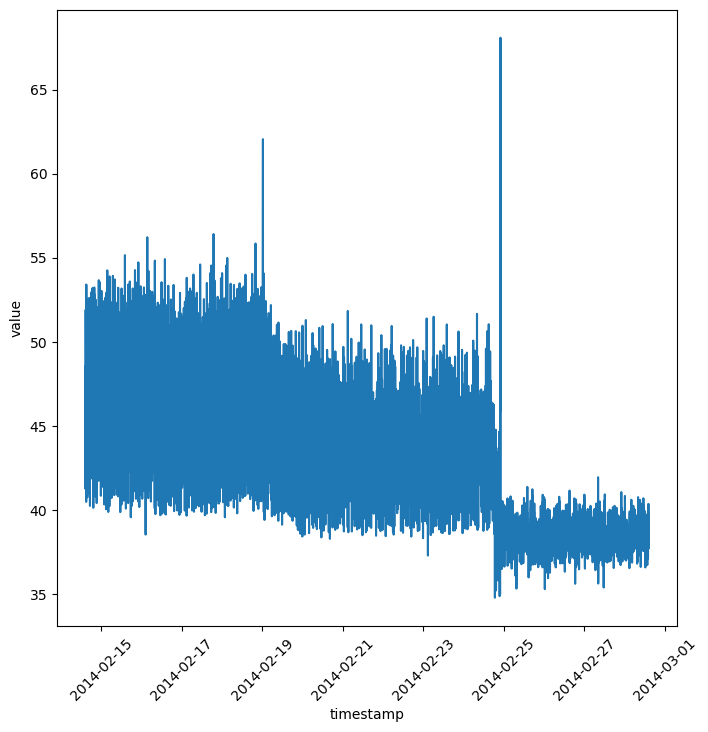

In [11]:
plt.figure(figsize = (8,8))
sns.lineplot(data = df, x = "timestamp", y = "value")
plt.xticks(rotation=45)
plt.show()

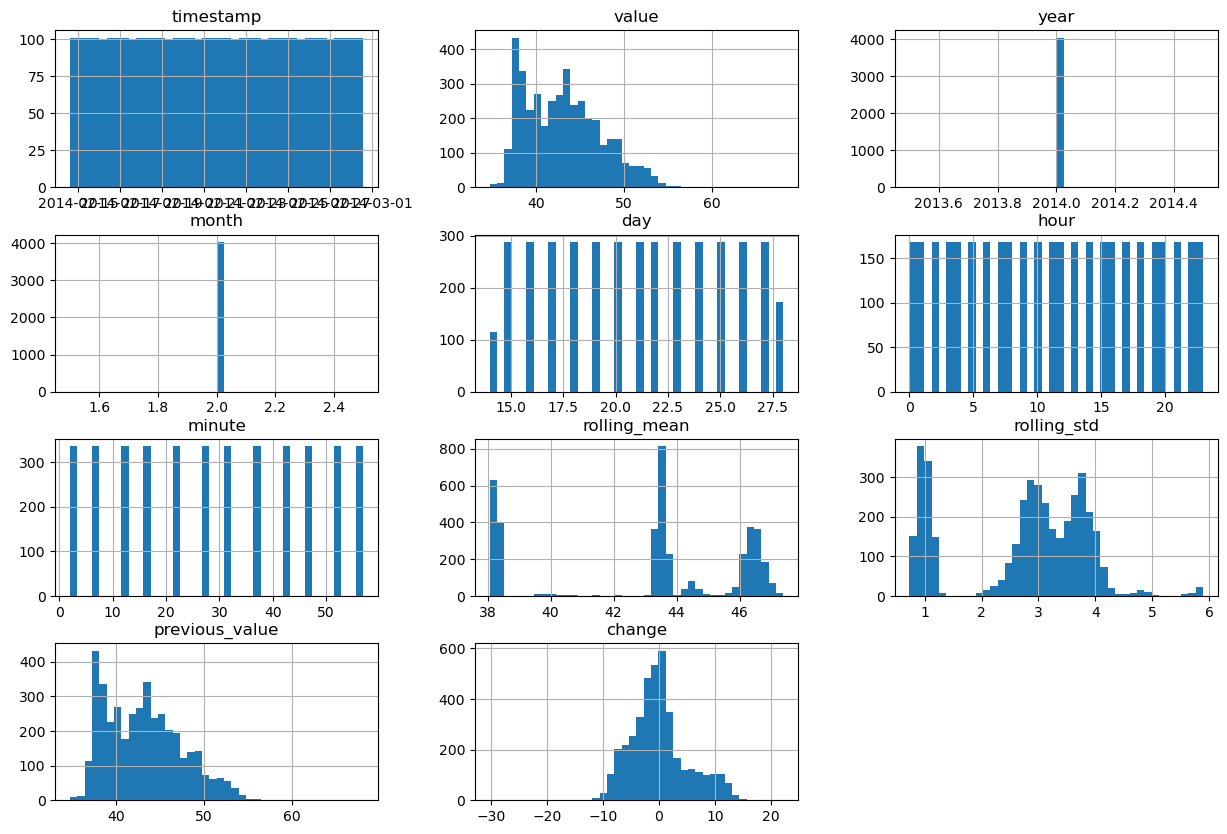

In [12]:
df.hist(bins = 40, figsize = (15,10))
plt.show()

In [13]:
df[["value","timestamp"]].sort_values(by = "value", ascending=False).head(10)

,value,timestamp
2970,68.092,2014-02-24 21:57:00
1271,62.056,2014-02-19 00:22:00
918,56.408,2014-02-17 18:57:00
444,56.220,2014-02-16 03:27:00
1218,55.846,2014-02-18 19:57:00
284,55.154,2014-02-15 14:07:00
1016,54.986,2014-02-18 03:07:00
570,54.918,2014-02-16 13:57:00
498,54.828,2014-02-16 07:57:00
380,54.722,2014-02-15 22:07:00


In [14]:
df[("2014-02-24 21:00:00" < df["timestamp"]) &  (df["timestamp"]< "2014-02-24 23:00:00")]

,timestamp,value,year,month,day,hour,minute,rolling_mean,rolling_std,previous_value,change
2959,2014-02-24 21:02:00,35.984,2014,2,24,21,2,39.721000,2.864617,41.502,-5.518
2960,2014-02-24 21:07:00,44.642,2014,2,24,21,7,39.724111,2.870044,35.984,8.658
2961,2014-02-24 21:12:00,39.340,2014,2,24,21,12,39.713167,2.870757,44.642,-5.302
2962,2014-02-24 21:17:00,37.794,2014,2,24,21,17,39.601222,2.864662,39.340,-1.546
2963,2014-02-24 21:22:00,40.688,2014,2,24,21,22,39.652944,2.867073,37.794,2.894
2964,2014-02-24 21:27:00,34.860,2014,2,24,21,27,39.550667,2.971605,40.688,-5.828
2965,2014-02-24 21:32:00,43.450,2014,2,24,21,32,39.604500,3.025223,34.860,8.590
2966,2014-02-24 21:37:00,39.482,2014,2,24,21,37,39.735500,2.909615,43.450,-3.968
2967,2014-02-24 21:42:00,34.954,2014,2,24,21,42,39.509222,2.956855,39.482,-4.528
2968,2014-02-24 21:47:00,50.728,2014,2,24,21,47,39.839833,3.494747,34.954,15.774


In [15]:
df[("2014-02-19 00:00:00" < df["timestamp"]) &  (df["timestamp"]< "2014-02-19 02:00:00")]

,timestamp,value,year,month,day,hour,minute,rolling_mean,rolling_std,previous_value,change
1267,2014-02-19 00:02:00,41.8780,2014,2,19,0,2,46.368333,3.813019,48.1560,-6.2780
1268,2014-02-19 00:07:00,53.0920,2014,2,19,0,7,46.491389,3.957887,41.8780,11.2140
1269,2014-02-19 00:12:00,50.0150,2014,2,19,0,12,46.761972,3.852252,53.0920,-3.0770
1270,2014-02-19 00:17:00,54.6033,2014,2,19,0,17,46.802453,3.928163,50.0150,4.5883
1271,2014-02-19 00:22:00,62.0560,2014,2,19,0,22,47.257342,4.672191,54.6033,7.4527
1272,2014-02-19 00:27:00,42.0860,2014,2,19,0,27,47.225953,4.703806,62.0560,-19.9700
1273,2014-02-19 00:32:00,50.8220,2014,2,19,0,32,47.263119,4.727385,42.0860,8.7360
1274,2014-02-19 00:37:00,44.5300,2014,2,19,0,37,47.387508,4.589113,50.8220,-6.2920
1275,2014-02-19 00:42:00,44.1320,2014,2,19,0,42,47.148231,4.525869,44.5300,-0.3980
1276,2014-02-19 00:47:00,47.1840,2014,2,19,0,47,47.219842,4.504842,44.1320,3.0520


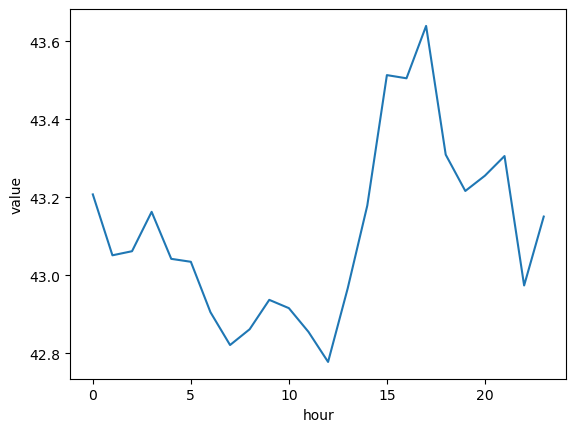

In [16]:
hour = df.groupby("hour")["value"].mean()
sns.lineplot(hour)
plt.show()

In [17]:
df["timestamp"].diff().value_counts()

timestamp
0 days 00:05:00    4031
Name: count, dtype: int64

In [18]:
df.groupby("day")["value"].mean()

day
14    46.829583
15    46.409910
16    46.325049
17    46.333660
18    46.601486
19    44.631376
20    43.457347
21    43.571743
22    43.472521
23    43.495090
24    42.716472
25    38.295292
26    38.263215
27    38.258319
28    38.313006
Name: value, dtype: float64

In [19]:
(("2014-02-18 16:02:00" < df["timestamp"]) &  (df["timestamp"]< "2014-02-19 08:42:00")).sum()

np.int64(199)

In [20]:
(("2014-02-24 10:17:00" < df["timestamp"]) &  (df["timestamp"]< "2014-02-25 02:57:00")).sum()

np.int64(199)

In [21]:
df["is_anomaly"] = ((("2014-02-18 16:02:00" < df["timestamp"]) &  (df["timestamp"]< "2014-02-19 08:42:00")) | (("2014-02-24 10:17:00" < df["timestamp"]) &  (df["timestamp"]< "2014-02-25 02:57:00"))).astype(int)

In [22]:
df.head()

,timestamp,value,year,month,day,hour,minute,rolling_mean,rolling_std,previous_value,change,is_anomaly
0,2014-02-14 14:27:00,51.846,2014,2,14,14,27,NaN,NaN,NaN,NaN,0
1,2014-02-14 14:32:00,44.508,2014,2,14,14,32,NaN,NaN,51.846,-7.338,0
2,2014-02-14 14:37:00,41.244,2014,2,14,14,37,NaN,NaN,44.508,-3.264,0
3,2014-02-14 14:42:00,48.568,2014,2,14,14,42,NaN,NaN,41.244,7.324,0
4,2014-02-14 14:47:00,46.714,2014,2,14,14,47,NaN,NaN,48.568,-1.854,0


In [23]:
df["is_anomaly"].value_counts()

is_anomaly
0    3634
1     398
Name: count, dtype: int64

In [24]:
df["prev_mean"] = df["rolling_mean"].shift(1)
df["prev_std"] = df["rolling_std"].shift(1)

In [25]:
df.head()

,timestamp,value,year,month,day,hour,minute,rolling_mean,rolling_std,previous_value,change,is_anomaly,prev_mean,prev_std
0,2014-02-14 14:27:00,51.846,2014,2,14,14,27,NaN,NaN,NaN,NaN,0,NaN,NaN
1,2014-02-14 14:32:00,44.508,2014,2,14,14,32,NaN,NaN,51.846,-7.338,0,NaN,NaN
2,2014-02-14 14:37:00,41.244,2014,2,14,14,37,NaN,NaN,44.508,-3.264,0,NaN,NaN
3,2014-02-14 14:42:00,48.568,2014,2,14,14,42,NaN,NaN,41.244,7.324,0,NaN,NaN
4,2014-02-14 14:47:00,46.714,2014,2,14,14,47,NaN,NaN,48.568,-1.854,0,NaN,NaN


In [26]:
df["score"] = ((df["value"] - df["prev_mean"]) / df["prev_std"]).abs() 

In [27]:
df["score"].describe()

count    3996.000000
mean        0.807005
std         0.646119
min         0.000049
25%         0.282821
50%         0.637548
75%         1.246899
max         7.768311
Name: score, dtype: float64

In [28]:
df[["timestamp","value","score","is_anomaly"]].sort_values(by = "score", ascending=False).head(10)

,timestamp,value,score,is_anomaly
2970,2014-02-24 21:57:00,68.092,7.768311,1
3668,2014-02-27 08:07:00,41.936,4.085371,0
1271,2014-02-19 00:22:00,62.056,3.883125,1
2968,2014-02-24 21:47:00,50.728,3.794159,1
2930,2014-02-24 18:37:00,34.766,3.449563,1
3834,2014-02-27 21:57:00,41.052,3.123113,0
3906,2014-02-28 03:57:00,40.598,3.086530,0
2259,2014-02-22 10:42:00,49.788,3.060318,0
3162,2014-02-25 13:57:00,41.362,3.056510,0
3570,2014-02-26 23:57:00,40.902,3.032198,0


In [29]:
df["predicted"] = (df["score"] > 3.4).astype(int)

In [30]:
df["predicted"].value_counts()

predicted
0    4027
1       5
Name: count, dtype: int64

In [31]:
df["predicted"].sum()

np.int64(5)

In [32]:
df[df["predicted"] == 1][["is_anomaly"]].value_counts()

is_anomaly
1             4
0             1
Name: count, dtype: int64

In [33]:
df["score"].notna().sum()

np.int64(3996)

In [34]:
X = df[["value"]][df["score"].notna()]

In [35]:
X.shape

(3996, 1)

In [36]:
from sklearn.ensemble import IsolationForest

In [37]:
df["is_anomaly"].value_counts(normalize=True)

is_anomaly
0    0.90129
1    0.09871
Name: proportion, dtype: float64

In [38]:
fraud_ratio = 0.09871

In [39]:
iso = IsolationForest(
    n_estimators=100,
    max_samples="auto",
    contamination=fraud_ratio,
    max_features=1.0,
    n_jobs= -1,
    random_state=42
)

In [40]:
iso.fit(X)

,n_estimators,100
,max_samples,'auto'
,contamination,0.09871
,max_features,1.0
,bootstrap,False
,n_jobs,-1
,random_state,42
,verbose,0
,warm_start,False


In [41]:
guess = iso.predict(X)

In [42]:
pd.Series(guess).value_counts()

 1    3602
-1     394
Name: count, dtype: int64

In [43]:
(guess == -1).astype(int)

array([0, 0, 0, ..., 0, 0, 0], shape=(3996,))

In [44]:
df["iso_pred"] = pd.Series((guess == -1).astype(int), index= X.index)

In [45]:
df[df["iso_pred"] == 1]["is_anomaly"].value_counts()

is_anomaly
0    339
1     55
Name: count, dtype: int64

In [46]:
df.groupby("day")["iso_pred"].mean()

day
14    0.202532
15    0.184028
16    0.194444
17    0.197917
18    0.201389
19    0.086806
20    0.017361
21    0.020833
22    0.006944
23    0.013889
24    0.069444
25    0.097222
26    0.090278
27    0.083333
28    0.080925
Name: iso_pred, dtype: float64

In [47]:
X2 = df[["value","score"]][df["score"].notna()]

In [48]:
X2.shape

(3996, 2)

In [49]:
iso2 = IsolationForest(
    n_estimators=100,
    max_samples="auto",
    contamination=0.002,
    max_features=1.0,
    n_jobs= -1,
    random_state=42
)

In [50]:
iso2.fit(X2)

,n_estimators,100
,max_samples,'auto'
,contamination,0.002
,max_features,1.0
,bootstrap,False
,n_jobs,-1
,random_state,42
,verbose,0
,warm_start,False


In [51]:
guess2 = iso2.predict(X2)

In [52]:
df["iso_pred2"] = pd.Series((guess2 == -1).astype(int), index= X.index)

In [53]:
df[df["iso_pred2"] == 1]["is_anomaly"].value_counts()

is_anomaly
1    4
0    4
Name: count, dtype: int64

In [54]:
df.groupby("day")["iso_pred2"].mean()

day
14    0.000000
15    0.000000
16    0.000000
17    0.000000
18    0.000000
19    0.003472
20    0.000000
21    0.000000
22    0.000000
23    0.000000
24    0.010417
25    0.003472
26    0.006944
27    0.003472
28    0.000000
Name: iso_pred2, dtype: float64

In [55]:
df[df["iso_pred2"] == 1][["timestamp", "value", "score", "is_anomaly"]]

,timestamp,value,score,is_anomaly
1271,2014-02-19 00:22:00,62.056,3.883125,1
2930,2014-02-24 18:37:00,34.766,3.449563,1
2935,2014-02-24 19:02:00,35.174,2.654659,1
2970,2014-02-24 21:57:00,68.092,7.768311,1
3084,2014-02-25 07:27:00,35.310,2.968323,0
3287,2014-02-26 00:22:00,35.278,2.636884,0
3504,2014-02-26 18:27:00,35.596,2.847309,0
3708,2014-02-27 11:27:00,35.376,2.955893,0


In [56]:
X_train = df[["score","value"]][(df["score"].notna()) & (df["timestamp"] < "2014-02-18 16:02:00")]
X_test = df[["score","value"]][(df["score"].notna()) & (df["timestamp"] >= "2014-02-18 16:02:00")] 

In [57]:
print(X_train.shape)
print(X_test.shape)

(1135, 2)
(2861, 2)


In [58]:
iso3 = IsolationForest(
    n_estimators=100,
    max_samples="auto",
    contamination=0.002,
    max_features=1.0,
    n_jobs= -1,
    random_state=42
)

In [59]:
iso3.fit(X_train)

,n_estimators,100
,max_samples,'auto'
,contamination,0.002
,max_features,1.0
,bootstrap,False
,n_jobs,-1
,random_state,42
,verbose,0
,warm_start,False


In [60]:
guess3 = iso3.predict(X_test)

In [61]:
df["iso_pred3"]  = pd.Series((guess3 == -1).astype(int), index= X_test.index)

In [62]:
df["iso_pred3"].sum()

np.float64(2.0)

In [63]:
df[df["iso_pred3"] == 1]["is_anomaly"].value_counts()

is_anomaly
1    2
Name: count, dtype: int64

In [64]:
df[df["iso_pred3"] == 1][["timestamp", "value", "score", "is_anomaly"]]

,timestamp,value,score,is_anomaly
1271,2014-02-19 00:22:00,62.056,3.883125,1
2970,2014-02-24 21:57:00,68.092,7.768311,1


In [65]:
iso4 = IsolationForest(
    n_estimators=100,
    max_samples="auto",
    contamination=0.005,
    max_features=1.0,
    n_jobs= -1,
    random_state=42
)

In [66]:
iso4.fit(X_train)

,n_estimators,100
,max_samples,'auto'
,contamination,0.005
,max_features,1.0
,bootstrap,False
,n_jobs,-1
,random_state,42
,verbose,0
,warm_start,False


In [67]:
guess4 = iso4.predict(X_test)

In [68]:
df["iso_pred4"]  = pd.Series((guess4 == -1).astype(int), index= X_test.index)

In [69]:
df["iso_pred4"].sum()

np.float64(17.0)

In [70]:
df[df["iso_pred4"] == 1]["is_anomaly"].value_counts()

is_anomaly
0    10
1     7
Name: count, dtype: int64

In [71]:
df[df["iso_pred4"] == 1][["timestamp", "value", "score", "is_anomaly"]]

,timestamp,value,score,is_anomaly
1218,2014-02-18 19:57:00,55.846,2.349054,1
1271,2014-02-19 00:22:00,62.056,3.883125,1
2080,2014-02-21 19:47:00,38.454,2.314451,0
2416,2014-02-22 23:47:00,38.310,2.373225,0
2848,2014-02-24 11:47:00,38.744,2.728103,1
2930,2014-02-24 18:37:00,34.766,3.449563,1
2935,2014-02-24 19:02:00,35.174,2.654659,1
2938,2014-02-24 19:17:00,35.254,2.360395,1
2970,2014-02-24 21:57:00,68.092,7.768311,1
3084,2014-02-25 07:27:00,35.310,2.968323,0


In [72]:
from itertools import product

contaminations = [0.001,0.002,0.003,0.005]
random_states = [42,7,123]
n_estimators_list = [50,100,200,300]
empty_list = []

for n,c,r in product(n_estimators_list, contaminations, random_states):
    model = IsolationForest(
        n_estimators=n,
        max_samples="auto",
        contamination=c,
        max_features=1.0,
        n_jobs= -1,
        random_state=r
    )
    model.fit(X_train)
    predictions = model.predict(X_test)
    anomaly_count = (predictions == -1).sum()
    anomaly_rate = anomaly_count / len(predictions)
    
    empty_list.append({
        "contamination": c,
        "random_state": r,
        "n_estimators": n,
        "anomaly_count": anomaly_count,
        "anomaly_rate": anomaly_rate,
    })
results_df = pd.DataFrame(empty_list) 

In [73]:
results_df.sort_values(by="anomaly_rate").drop(columns=["model"])

,contamination,random_state,n_estimators,anomaly_count,anomaly_rate
0,0.001,42,50,2,0.000699
38,0.001,123,300,2,0.000699
37,0.001,7,300,2,0.000699
36,0.001,42,300,2,0.000699
28,0.002,7,200,2,0.000699
27,0.002,42,200,2,0.000699
26,0.001,123,200,2,0.000699
25,0.001,7,200,2,0.000699
24,0.001,42,200,2,0.000699
39,0.002,42,300,2,0.000699


In [74]:
predictions

array([1, 1, 1, ..., 1, 1, 1], shape=(2861,))

In [75]:
df["iso_pred5"] = pd.Series((predictions == -1).astype(int), index = X_test.index)

In [76]:
df["iso_pred5"].sum()

np.float64(17.0)

In [86]:
((df["iso_pred5"] == 1) & (df["is_anomaly"] == 1)).sum()

np.int64(7)

In [87]:
((df["iso_pred5"] == 1) & (df["is_anomaly"] == 0)).sum()

np.int64(10)

In [91]:
df[(df["iso_pred5"] == 1) & (df["timestamp"] >= "2014-02-18 16:02") & (df["timestamp"] <= "2014-02-19 08:42")]

,timestamp,value,year,month,day,hour,minute,rolling_mean,rolling_std,previous_value,...,is_anomaly,prev_mean,prev_std,score,predicted,iso_pred,iso_pred2,iso_pred3,iso_pred4,iso_pred5
1218,2014-02-18 19:57:00,55.846,2014,2,18,19,57,46.839167,4.233202,40.5600,...,1,46.586778,3.941682,2.349054,0,1.0,0.0,0.0,1.0,1.0
1271,2014-02-19 00:22:00,62.056,2014,2,19,0,22,47.257342,4.672191,54.6033,...,1,46.802453,3.928163,3.883125,1,1.0,1.0,1.0,1.0,1.0


In [92]:
df[(df["iso_pred5"] == 1) & (df["timestamp"] >= "2014-02-24 10:17") & (df["timestamp"] <= "2014-02-25 02:57")]

,timestamp,value,year,month,day,hour,minute,rolling_mean,rolling_std,previous_value,...,is_anomaly,prev_mean,prev_std,score,predicted,iso_pred,iso_pred2,iso_pred3,iso_pred4,iso_pred5
2848,2014-02-24 11:47:00,38.744,2014,2,24,11,47,43.551778,1.940921,44.746,...,1,43.784222,1.847519,2.728103,0,0.0,0.0,0.0,1.0,1.0
2930,2014-02-24 18:37:00,34.766,2014,2,24,18,37,42.998722,2.831169,41.512,...,1,43.232389,2.454337,3.449563,1,1.0,1.0,0.0,1.0,1.0
2935,2014-02-24 19:02:00,35.174,2014,2,24,19,2,42.368167,3.052853,42.982,...,1,42.609833,2.801051,2.654659,0,1.0,1.0,0.0,1.0,1.0
2938,2014-02-24 19:17:00,35.254,2014,2,24,19,17,42.043389,3.184547,39.766,...,1,42.255444,2.966218,2.360395,0,1.0,0.0,0.0,1.0,1.0
2970,2014-02-24 21:57:00,68.092,2014,2,24,21,57,40.778611,5.888828,45.892,...,1,40.081111,3.605789,7.768311,1,1.0,1.0,1.0,1.0,1.0


In [93]:
alarm = pd.Series((predictions == -1), index = X_test.index)

In [94]:
alarm.sum()

np.int64(17)

In [95]:
(alarm & (df.loc[X_test.index, "is_anomaly"] == 1)).sum()

np.int64(7)

In [96]:
(alarm & (df.loc[X_test.index, "is_anomaly"] == 0)).sum()

np.int64(10)

In [97]:
t = df.loc[X_test.index, "timestamp"]
(alarm & (t >= "2014-02-18 16:02") & (t <= "2014-02-19 08:42")).sum()

np.int64(2)

In [98]:
(alarm & (t >= "2014-02-24 10:17") & (t <= "2014-02-25 02:57")).sum()

np.int64(5)

In [104]:
t = df.loc[X_test.index, "timestamp"]
contaminations = [0.001,0.002,0.003,0.005]
random_states = [42,7,123]
n_estimators_list = [50,100,200,300]
empty_list = []

for n,c,r in product(n_estimators_list, contaminations, random_states):
    model = IsolationForest(
        n_estimators=n,
        max_samples="auto",
        contamination=c,
        max_features=1.0,
        n_jobs= -1,
        random_state=r
    )
    model.fit(X_train)
    predictions = model.predict(X_test)
    anomaly_count = (predictions == -1).sum()
    anomaly_rate = anomaly_count / len(predictions)
    alarm = pd.Series(predictions == -1, index=X_test.index)
    true_alarm = (alarm & (df.loc[X_test.index, "is_anomaly"] == 1)).sum()
    false_alarm = (alarm & (df.loc[X_test.index, "is_anomaly"] == 0)).sum()
    w1 = (alarm & (t >= "2014-02-18 16:02") & (t <= "2014-02-19 08:42")).sum()
    w2 = (alarm & (t >= "2014-02-24 10:17") & (t <= "2014-02-25 02:57")).sum()
    
    empty_list.append({
        "contamination": c,
        "random_state": r,
        "n_estimators": n,
        "anomaly_count": anomaly_count,
        "anomaly_rate": anomaly_rate,
        "true_alarm": true_alarm,
        "false_alarm": false_alarm,
        "windows_caught": int(w1 > 0) + int(w2 > 0),
    })
results_df = pd.DataFrame(empty_list) 

In [105]:
results_df.shape

(48, 8)

In [106]:
results_df.sort_values(by = "false_alarm")

,contamination,random_state,n_estimators,anomaly_count,anomaly_rate,true_alarm,false_alarm,windows_caught
0,0.001,42,50,2,0.000699,2,0,2
36,0.001,42,300,2,0.000699,2,0,2
39,0.002,42,300,2,0.000699,2,0,2
40,0.002,7,300,2,0.000699,2,0,2
31,0.003,7,200,3,0.001049,3,0,2
29,0.002,123,200,3,0.001049,3,0,2
28,0.002,7,200,2,0.000699,2,0,2
27,0.002,42,200,2,0.000699,2,0,2
26,0.001,123,200,2,0.000699,2,0,2
25,0.001,7,200,2,0.000699,2,0,2


In [107]:
results_df["windows_caught"].value_counts()

windows_caught
2    48
Name: count, dtype: int64

In [109]:
results_df.groupby("contamination")[["anomaly_count", "true_alarm", "false_alarm"]].agg(["min", "max"])

anomaly_count     true_alarm     false_alarm    
                        min max        min max         min max
contamination                                                 
0.001                     2   2          2   2           0   0
0.002                     2   3          2   3           0   0
0.003                     3  17          3   7           0  10
0.005                    13  17          6   7           7  10